# IMAP DATA ANALYSIS
##  *TODO LIST*

- [ ] Analysis of time-series data in chosen timespan,
- [ ] Analysis of the data distribution,
- [ ] Linear correlations between parameters from specific instrument,
- [ ] Linear correlations between parameters from different instruments,
- [ ] Non-linear correlations between parameters from specific instrument,
- [ ] Non-linear correlations between parameters from different instruments,
- [ ] PCA Analysis of data per instrument,
- [ ] TSNE Analysis of data per instrument,
- [ ] MI Analysis of data between instruments,

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import sklearn
import os
import cdflib
from pathlib import Path

In [30]:
def plot_time_series(cdf_var_name, data_dir="../raw_data/ARCHIVE/All", component=None, gap_factor=10,):

    data_dir = Path(data_dir)
    cdf_files = sorted(p for p in data_dir.iterdir() if p.is_file() and p.suffix.lower() == ".cdf")
    if not cdf_files:
        raise FileNotFoundError(f"No CDF files found in {data_dir}")
    all_time = []
    all_values = []
    metadata = None
    files_found = 0
    for file in cdf_files:
        cdf = cdflib.CDF(str(file))
        try:
            variables = cdf.cdf_info().zVariables
            if cdf_var_name not in variables:
                continue
            attrs = cdf.varattsget(cdf_var_name)
            epoch_name = attrs.get("DEPEND_0")
            if not epoch_name or epoch_name not in variables:
                print(f"Skipped {file.name}: missing DEPEND_0")
                continue

            epoch = np.asarray(cdf.varget(epoch_name))
            values = np.asarray(cdf.varget(cdf_var_name))
            if values.ndim == 0 or values.shape[0] != len(epoch):
                print(f"Skipped {file.name}: incompatible time dimension")
                continue

            valid_time = epoch != np.iinfo(np.int64).min
            epoch = epoch[valid_time]
            values = values[valid_time]
            values = values.astype(float, copy=True)
            fill_value = attrs.get("FILLVAL")
            if fill_value is not None:
                values[values == float(fill_value)] = np.nan

            values[~np.isfinite(values)] = np.nan
            if component is not None:
                if isinstance(component, int):
                    component = (component,)
                values = values[(slice(None),) + tuple(component)]
            elif values.ndim > 2:
                raise ValueError(f"{cdf_var_name} has shape {values.shape}; select a component explicitly.")

            if len(epoch) == 0:
                continue

            all_time.append(epoch)
            all_values.append(values)
            files_found += 1
            file_start = cdflib.cdfepoch.to_datetime(epoch.min())
            file_end = cdflib.cdfepoch.to_datetime(epoch.max())
            print(f"{file.name}: {file_start} -> {file_end} ({len(epoch)} samples)")
            if metadata is None:
                metadata = attrs

        except Exception as ex:
            print(ex)

    if not all_time:
        raise ValueError(f"No valid data found for '{cdf_var_name}'.")

    print(f"\nFiles used: {files_found}/{len(cdf_files)}")

    all_time = np.concatenate(all_time)
    all_values = np.concatenate(all_values, axis=0)
    order = np.argsort(all_time)
    all_time = all_time[order]
    all_values = all_values[order]
    time = cdflib.cdfepoch.to_datetime(all_time)

    if all_values.ndim == 1:
        all_values = all_values[:, None]
    else:
        all_values = all_values.reshape(len(all_values), -1)

    if len(all_time) > 1 and gap_factor is not None:
        differences = np.diff(all_time)
        positive_differences = differences[differences > 0]

        if len(positive_differences):
            median_dt = np.median(positive_differences)
            gap_indices = np.where(differences > gap_factor * median_dt)[0]
            all_values[gap_indices + 1, :] = np.nan

    label = metadata.get("LABLAXIS", cdf_var_name)
    units = metadata.get("UNITS", "")
    description = metadata.get("CATDESC", cdf_var_name)
    fig, ax = plt.subplots(figsize=(16, 7))

    for i in range(all_values.shape[1]):
        line_label = (label if all_values.shape[1] == 1 else f"{label} — component {i}")
        ax.plot(time, all_values[:, i], linewidth=0.8, label=line_label,)

    ax.set_title(f"{description}\n({cdf_var_name})")
    ax.set_xlabel("Time")
    ax.set_ylabel(f"{label} [{units}]" if str(units).strip() else label)
    ax.grid(True, alpha=0.3)
    if all_values.shape[1] > 1:
        ax.legend()

    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()
    columns = ([cdf_var_name] if all_values.shape[1] == 1 else [f"{cdf_var_name}_{i}" for i in range(all_values.shape[1])])
    return pd.DataFrame(all_values, index=pd.DatetimeIndex(time, name="time"), columns=columns,)

imap_ialirt_l1_realtime_20260201_v001.cdf: ['2026-02-01T00:00:00.899061760'] -> ['2026-02-01T15:48:20.852364800'] (9614 samples)
imap_ialirt_l1_realtime_20260202_v001.cdf: ['2026-02-02T08:04:24.789594880'] -> ['2026-02-02T23:59:56.739892608'] (8075 samples)
imap_ialirt_l1_realtime_20260203_v001.cdf: ['2026-02-03T00:00:00.739858560'] -> ['2026-02-03T15:57:40.688673920'] (8869 samples)
imap_ialirt_l1_realtime_20260204_v001.cdf: ['2026-02-04T07:57:44.635151232'] -> ['2026-02-04T22:59:48.613788160'] (8788 samples)
imap_ialirt_l1_realtime_20260205_v001.cdf: ['2026-02-05T07:55:12.305690496'] -> ['2026-02-05T16:34:48.507399680'] (7771 samples)
imap_ialirt_l1_realtime_20260206_v001.cdf: ['2026-02-06T07:51:48.477544576'] -> ['2026-02-06T18:59:48.592213632'] (9916 samples)
imap_ialirt_l1_realtime_20260207_v001.cdf: ['2026-02-07T07:48:40.148983552'] -> ['2026-02-07T16:15:04.357126272'] (7597 samples)
imap_ialirt_l1_realtime_20260208_v001.cdf: ['2026-02-08T07:45:32.319591424'] -> ['2026-02-08T23:5

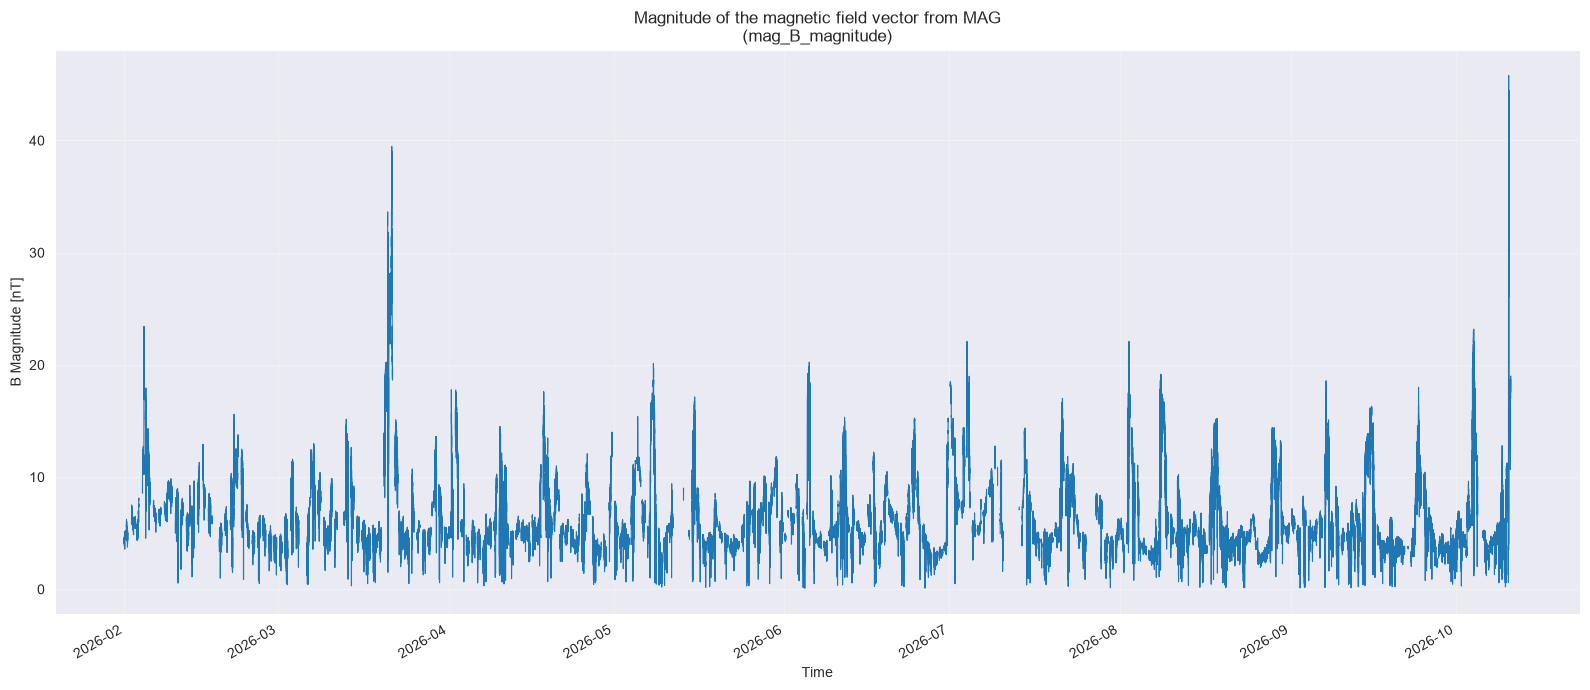

imap_ialirt_l1_realtime_20260201_v001.cdf: ['2026-02-01T00:00:00.899061760'] -> ['2026-02-01T15:48:20.852364800'] (9614 samples)
imap_ialirt_l1_realtime_20260202_v001.cdf: ['2026-02-02T08:04:24.789594880'] -> ['2026-02-02T23:59:56.739892608'] (8075 samples)
imap_ialirt_l1_realtime_20260203_v001.cdf: ['2026-02-03T00:00:00.739858560'] -> ['2026-02-03T15:57:40.688673920'] (8869 samples)
imap_ialirt_l1_realtime_20260204_v001.cdf: ['2026-02-04T07:57:44.635151232'] -> ['2026-02-04T22:59:48.613788160'] (8788 samples)
imap_ialirt_l1_realtime_20260205_v001.cdf: ['2026-02-05T07:55:12.305690496'] -> ['2026-02-05T16:34:48.507399680'] (7771 samples)
imap_ialirt_l1_realtime_20260206_v001.cdf: ['2026-02-06T07:51:48.477544576'] -> ['2026-02-06T18:59:48.592213632'] (9916 samples)
imap_ialirt_l1_realtime_20260207_v001.cdf: ['2026-02-07T07:48:40.148983552'] -> ['2026-02-07T16:15:04.357126272'] (7597 samples)
imap_ialirt_l1_realtime_20260208_v001.cdf: ['2026-02-08T07:45:32.319591424'] -> ['2026-02-08T23:5

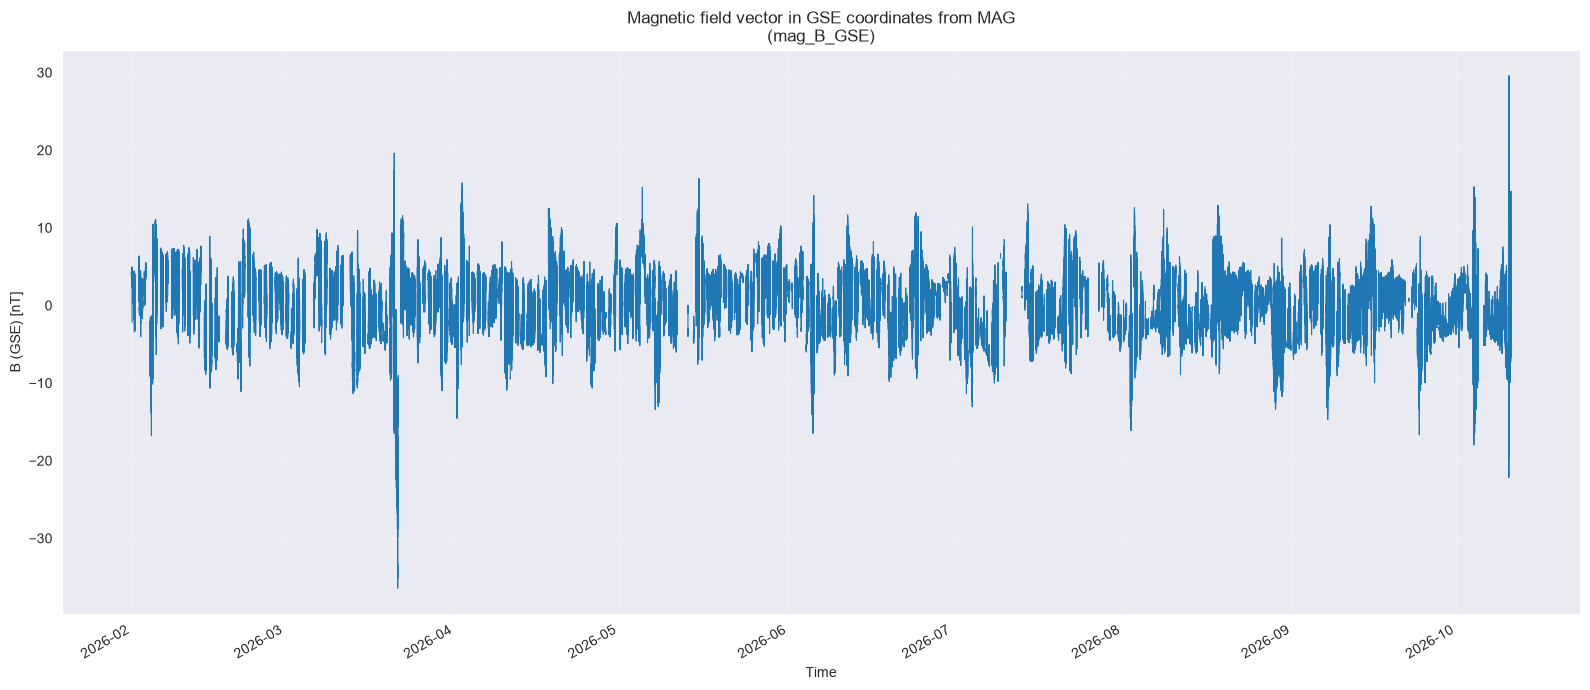

imap_ialirt_l1_realtime_20260201_v001.cdf: ['2026-02-01T00:00:00.899061760'] -> ['2026-02-01T15:48:20.852364800'] (9614 samples)
imap_ialirt_l1_realtime_20260202_v001.cdf: ['2026-02-02T08:04:24.789594880'] -> ['2026-02-02T23:59:56.739892608'] (8075 samples)
imap_ialirt_l1_realtime_20260203_v001.cdf: ['2026-02-03T00:00:00.739858560'] -> ['2026-02-03T15:57:40.688673920'] (8869 samples)
imap_ialirt_l1_realtime_20260204_v001.cdf: ['2026-02-04T07:57:44.635151232'] -> ['2026-02-04T22:59:48.613788160'] (8788 samples)
imap_ialirt_l1_realtime_20260205_v001.cdf: ['2026-02-05T07:55:12.305690496'] -> ['2026-02-05T16:34:48.507399680'] (7771 samples)
imap_ialirt_l1_realtime_20260206_v001.cdf: ['2026-02-06T07:51:48.477544576'] -> ['2026-02-06T18:59:48.592213632'] (9916 samples)
imap_ialirt_l1_realtime_20260207_v001.cdf: ['2026-02-07T07:48:40.148983552'] -> ['2026-02-07T16:15:04.357126272'] (7597 samples)
imap_ialirt_l1_realtime_20260208_v001.cdf: ['2026-02-08T07:45:32.319591424'] -> ['2026-02-08T23:5

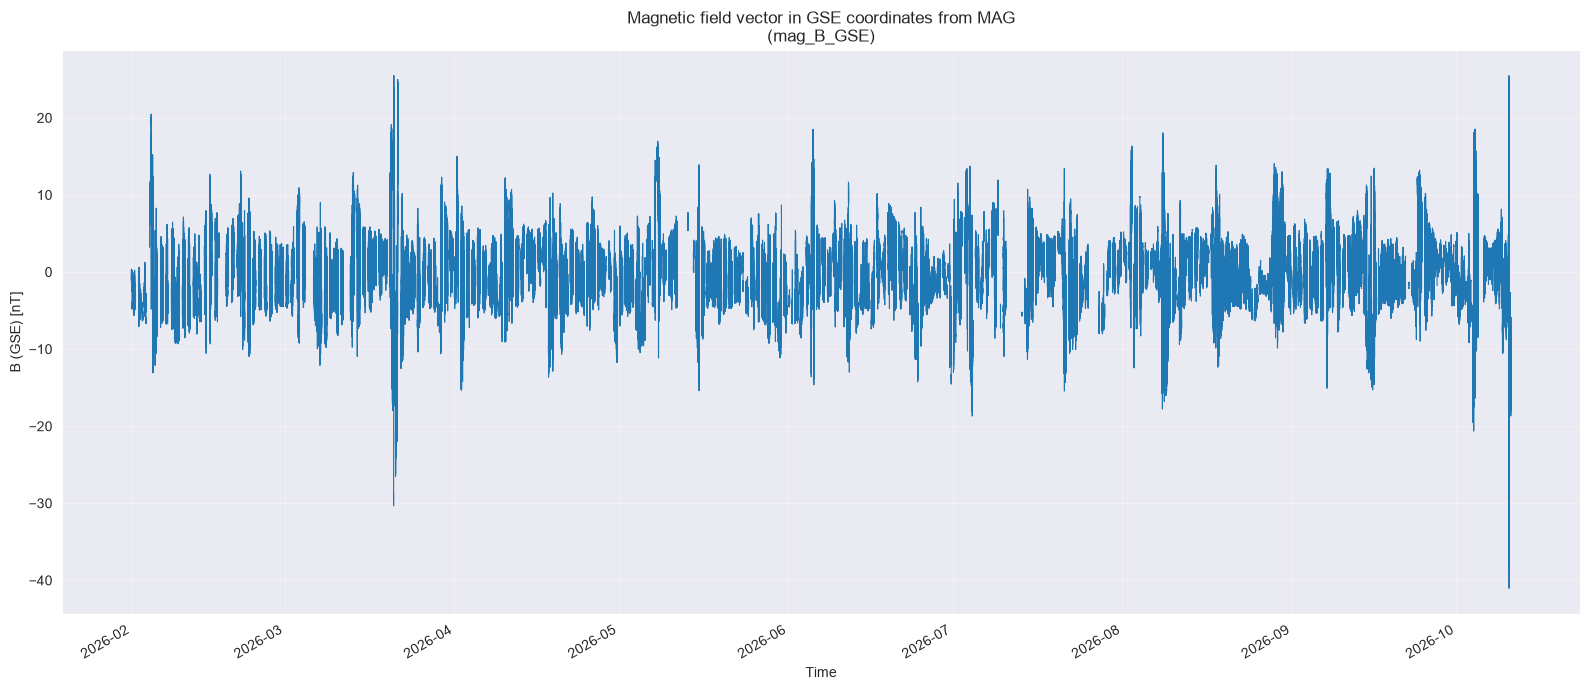

imap_ialirt_l1_realtime_20260201_v001.cdf: ['2026-02-01T00:00:00.899061760'] -> ['2026-02-01T15:48:20.852364800'] (9614 samples)
imap_ialirt_l1_realtime_20260202_v001.cdf: ['2026-02-02T08:04:24.789594880'] -> ['2026-02-02T23:59:56.739892608'] (8075 samples)
imap_ialirt_l1_realtime_20260203_v001.cdf: ['2026-02-03T00:00:00.739858560'] -> ['2026-02-03T15:57:40.688673920'] (8869 samples)
imap_ialirt_l1_realtime_20260204_v001.cdf: ['2026-02-04T07:57:44.635151232'] -> ['2026-02-04T22:59:48.613788160'] (8788 samples)
imap_ialirt_l1_realtime_20260205_v001.cdf: ['2026-02-05T07:55:12.305690496'] -> ['2026-02-05T16:34:48.507399680'] (7771 samples)
imap_ialirt_l1_realtime_20260206_v001.cdf: ['2026-02-06T07:51:48.477544576'] -> ['2026-02-06T18:59:48.592213632'] (9916 samples)
imap_ialirt_l1_realtime_20260207_v001.cdf: ['2026-02-07T07:48:40.148983552'] -> ['2026-02-07T16:15:04.357126272'] (7597 samples)
imap_ialirt_l1_realtime_20260208_v001.cdf: ['2026-02-08T07:45:32.319591424'] -> ['2026-02-08T23:5

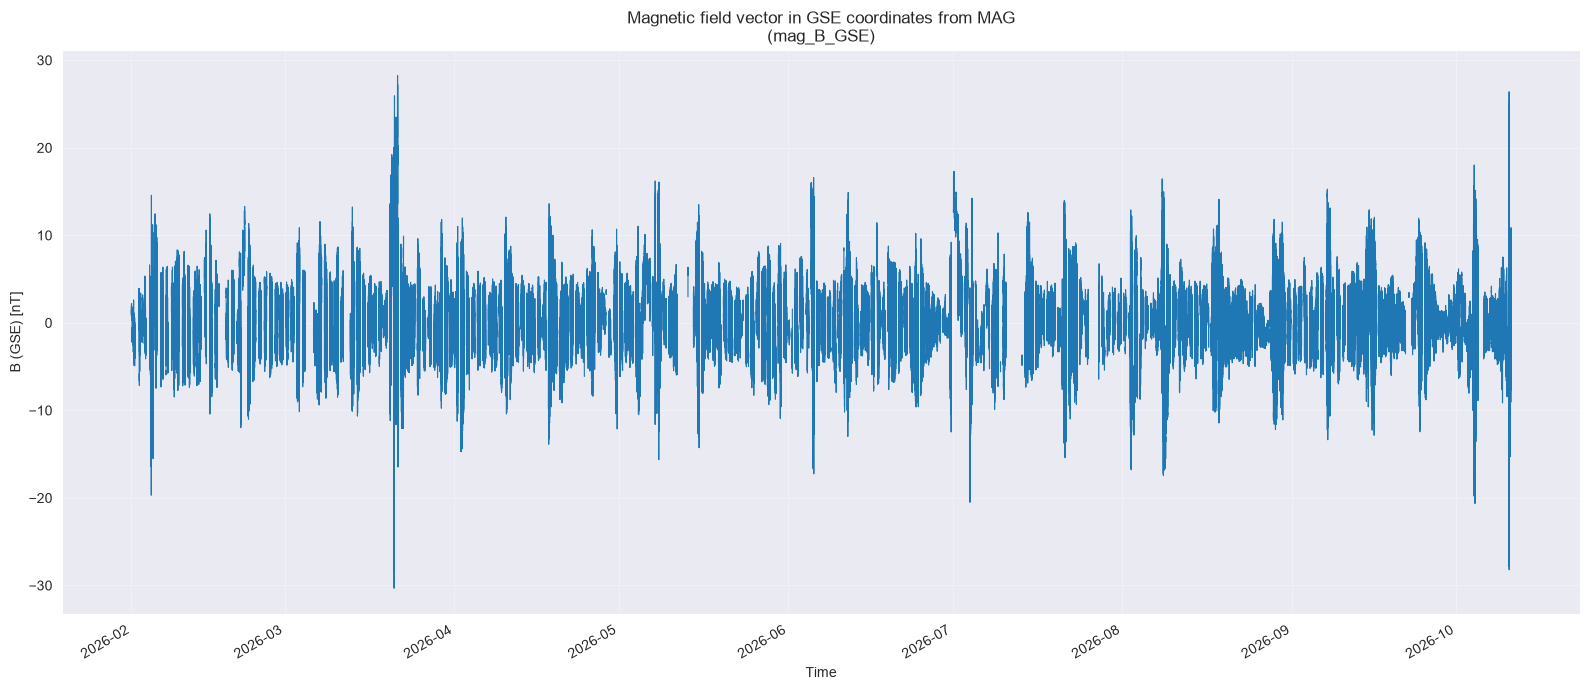

imap_ialirt_l1_realtime_20260201_v001.cdf: ['2026-02-01T00:00:00.899061760'] -> ['2026-02-01T15:48:20.852364800'] (9614 samples)
imap_ialirt_l1_realtime_20260202_v001.cdf: ['2026-02-02T08:04:24.789594880'] -> ['2026-02-02T23:59:56.739892608'] (8075 samples)
imap_ialirt_l1_realtime_20260203_v001.cdf: ['2026-02-03T00:00:00.739858560'] -> ['2026-02-03T15:57:40.688673920'] (8869 samples)
imap_ialirt_l1_realtime_20260204_v001.cdf: ['2026-02-04T07:57:44.635151232'] -> ['2026-02-04T22:59:48.613788160'] (8788 samples)
imap_ialirt_l1_realtime_20260205_v001.cdf: ['2026-02-05T07:55:12.305690496'] -> ['2026-02-05T16:34:48.507399680'] (7771 samples)
imap_ialirt_l1_realtime_20260206_v001.cdf: ['2026-02-06T07:51:48.477544576'] -> ['2026-02-06T18:59:48.592213632'] (9916 samples)
imap_ialirt_l1_realtime_20260207_v001.cdf: ['2026-02-07T07:48:40.148983552'] -> ['2026-02-07T16:15:04.357126272'] (7597 samples)
imap_ialirt_l1_realtime_20260208_v001.cdf: ['2026-02-08T07:45:32.319591424'] -> ['2026-02-08T23:5

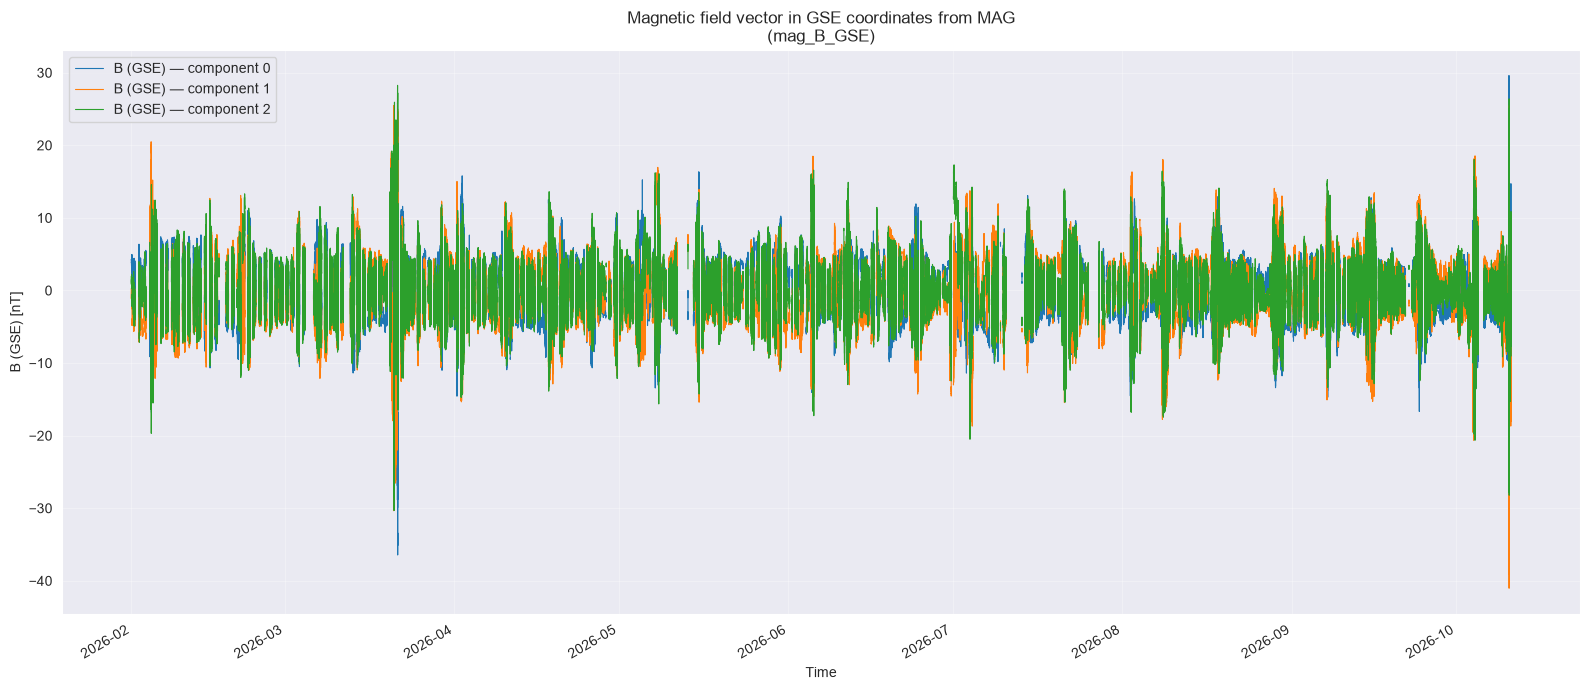

imap_ialirt_l1_realtime_20260201_v001.cdf: ['2026-02-01T00:00:00.899061760'] -> ['2026-02-01T15:48:20.852364800'] (9614 samples)
imap_ialirt_l1_realtime_20260202_v001.cdf: ['2026-02-02T08:04:24.789594880'] -> ['2026-02-02T23:59:56.739892608'] (8075 samples)
imap_ialirt_l1_realtime_20260203_v001.cdf: ['2026-02-03T00:00:00.739858560'] -> ['2026-02-03T15:57:40.688673920'] (8869 samples)
imap_ialirt_l1_realtime_20260204_v001.cdf: ['2026-02-04T07:57:44.635151232'] -> ['2026-02-04T22:59:48.613788160'] (8788 samples)
imap_ialirt_l1_realtime_20260205_v001.cdf: ['2026-02-05T07:55:12.305690496'] -> ['2026-02-05T16:34:48.507399680'] (7771 samples)
imap_ialirt_l1_realtime_20260206_v001.cdf: ['2026-02-06T07:51:48.477544576'] -> ['2026-02-06T18:59:48.592213632'] (9916 samples)
imap_ialirt_l1_realtime_20260207_v001.cdf: ['2026-02-07T07:48:40.148983552'] -> ['2026-02-07T16:15:04.357126272'] (7597 samples)
imap_ialirt_l1_realtime_20260208_v001.cdf: ['2026-02-08T07:45:32.319591424'] -> ['2026-02-08T23:5

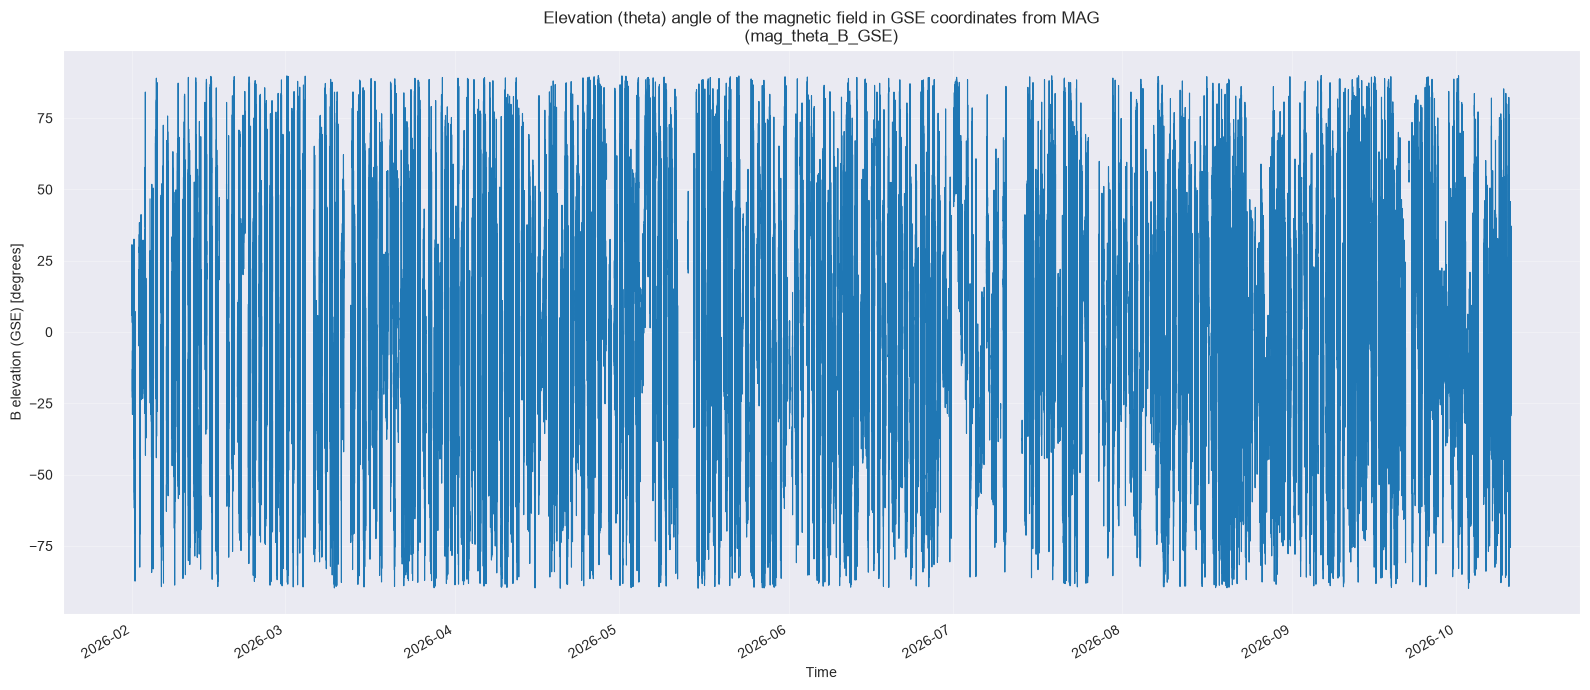

imap_ialirt_l1_realtime_20260201_v001.cdf: ['2026-02-01T00:00:00.899061760'] -> ['2026-02-01T15:48:20.852364800'] (9614 samples)
imap_ialirt_l1_realtime_20260202_v001.cdf: ['2026-02-02T08:04:24.789594880'] -> ['2026-02-02T23:59:56.739892608'] (8075 samples)
imap_ialirt_l1_realtime_20260203_v001.cdf: ['2026-02-03T00:00:00.739858560'] -> ['2026-02-03T15:57:40.688673920'] (8869 samples)
imap_ialirt_l1_realtime_20260204_v001.cdf: ['2026-02-04T07:57:44.635151232'] -> ['2026-02-04T22:59:48.613788160'] (8788 samples)
imap_ialirt_l1_realtime_20260205_v001.cdf: ['2026-02-05T07:55:12.305690496'] -> ['2026-02-05T16:34:48.507399680'] (7771 samples)
imap_ialirt_l1_realtime_20260206_v001.cdf: ['2026-02-06T07:51:48.477544576'] -> ['2026-02-06T18:59:48.592213632'] (9916 samples)
imap_ialirt_l1_realtime_20260207_v001.cdf: ['2026-02-07T07:48:40.148983552'] -> ['2026-02-07T16:15:04.357126272'] (7597 samples)
imap_ialirt_l1_realtime_20260208_v001.cdf: ['2026-02-08T07:45:32.319591424'] -> ['2026-02-08T23:5

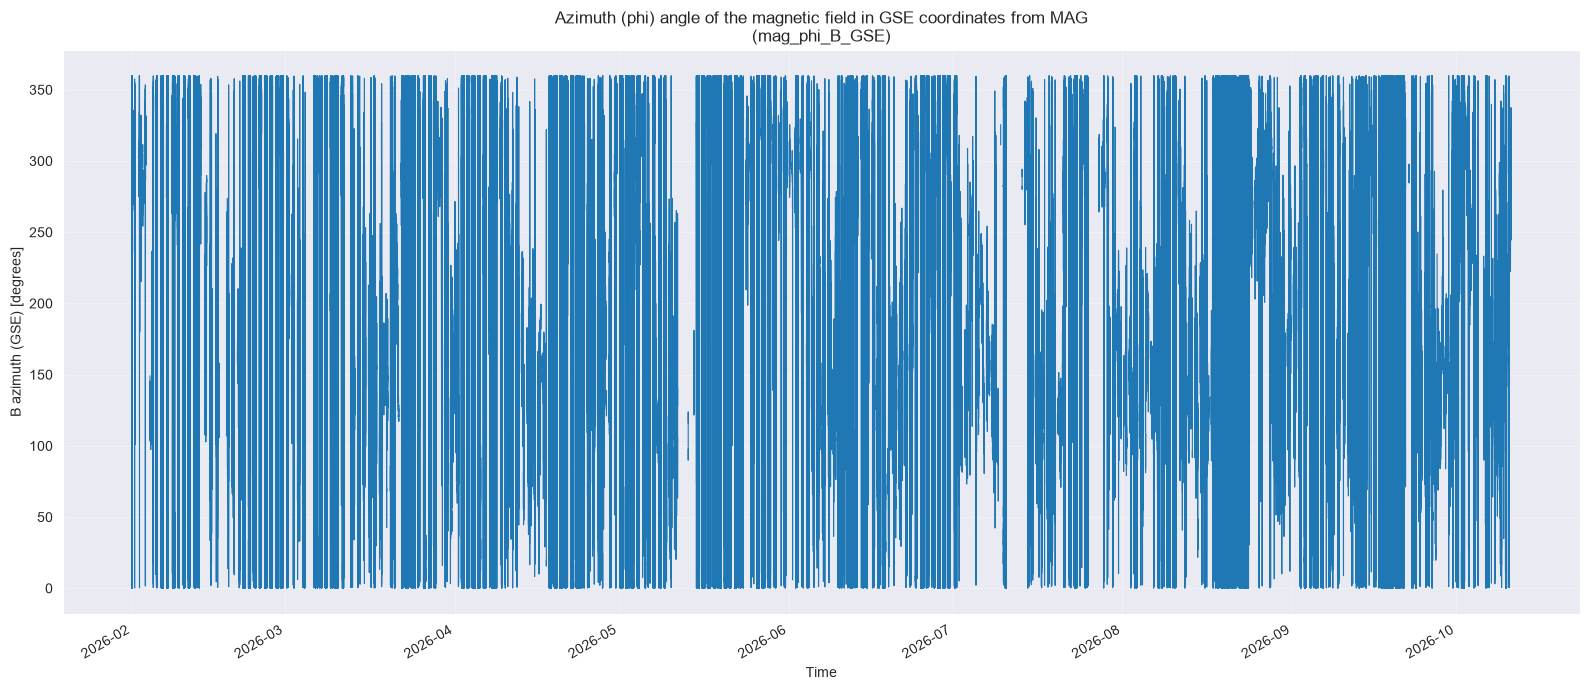

In [37]:
df = plot_time_series("mag_B_magnitude")
df2 = plot_time_series("mag_B_GSE", component=0)
df3 = plot_time_series("mag_B_GSE", component=1)
df4 = plot_time_series("mag_B_GSE", component=2)
df5 = plot_time_series("mag_B_GSE")
df6 = plot_time_series("mag_theta_B_GSE")
df7 = plot_time_series("mag_phi_B_GSE")



In [4]:
info = cdf.cdf_info()
for var in info.zVariables:
    var_info = cdf.varinq(var)
    attrs = cdf.varattsget(var)
    print(f"\n{'=' * 80}")
    print(f"VARIABLE: {var}")
    print(f"{var_info}")
    print(f"ATTRIBUTES: {attrs}")
    print(f"{'=' * 80}")


VARIABLE: codice_hi_h
VDRInfo(Variable='codice_hi_h', Num=0, Var_Type='zVariable', Data_Type=44, Data_Type_Description='CDF_FLOAT', Num_Elements=1, Num_Dims=3, Dim_Sizes=[15, 4, 4], Sparse='No_sparse', Last_Rec=845, Rec_Vary=True, Dim_Vary=[-1, -1, -1], Compress=0, Pad=array([-1.e+30], dtype=float32), Block_Factor=1)
ATTRIBUTES: {'DEPEND_0': 'codice_hi_epoch', 'DISPLAY_TYPE': 'no_plot', 'FILLVAL': np.float32(-1e+31), 'FORMAT': 'F11.1', 'VALIDMIN': np.float32(0.0), 'VALIDMAX': np.float32(1e+08), 'VAR_TYPE': 'data', 'UNITS': 'counts / cm2-sr-s-MeV', 'dtype': 'float32', 'CATDESC': 'Proton flux from CoDICE-Hi in 15 energy bins between 0.02 to 3.62 MeV over 4 spin angles and 4 polar angles', 'FIELDNAM': 'H+ intensity', 'LABLAXIS': 'H+ intensity', 'DEPEND_1': 'codice_hi_energy_center', 'DEPEND_2': 'codice_hi_spin_sector', 'DEPEND_3': 'codice_hi_polar', 'VAR_NOTES': 'Energy ranges (MeV) are 0.0200 to 0.0283, 0.0283 to 0.0400, 0.0400 to 0.0566, 0.0566 to 0.0800, 0.0800 to 0.113, 0.113 to 0.16

### MAG
MAG - Magnetometer - is a one of the most basic instruments found on IMAP. This device monitors changes in the magnetic field in the proximity of the spacecraft. Because of its design where the detector is attached to the boom situated away from the spacecraft itself, it detects only the environmental changes of the magnetic fields without the magnetic field generated by the spacecraft.
We are going to check how $B$ (magnitude) changes in relation to time and position of the IMAP satellite.

GSE explenation [here](https://www.researchgate.net/figure/The-diagram-shows-the-Geocentric-Solar-Ecliptic-GSE-coordinate-system-centered-at-the_fig1_334136287)


![GSE diagram](../res/GSE.png)


;isajous curves around the L1 point

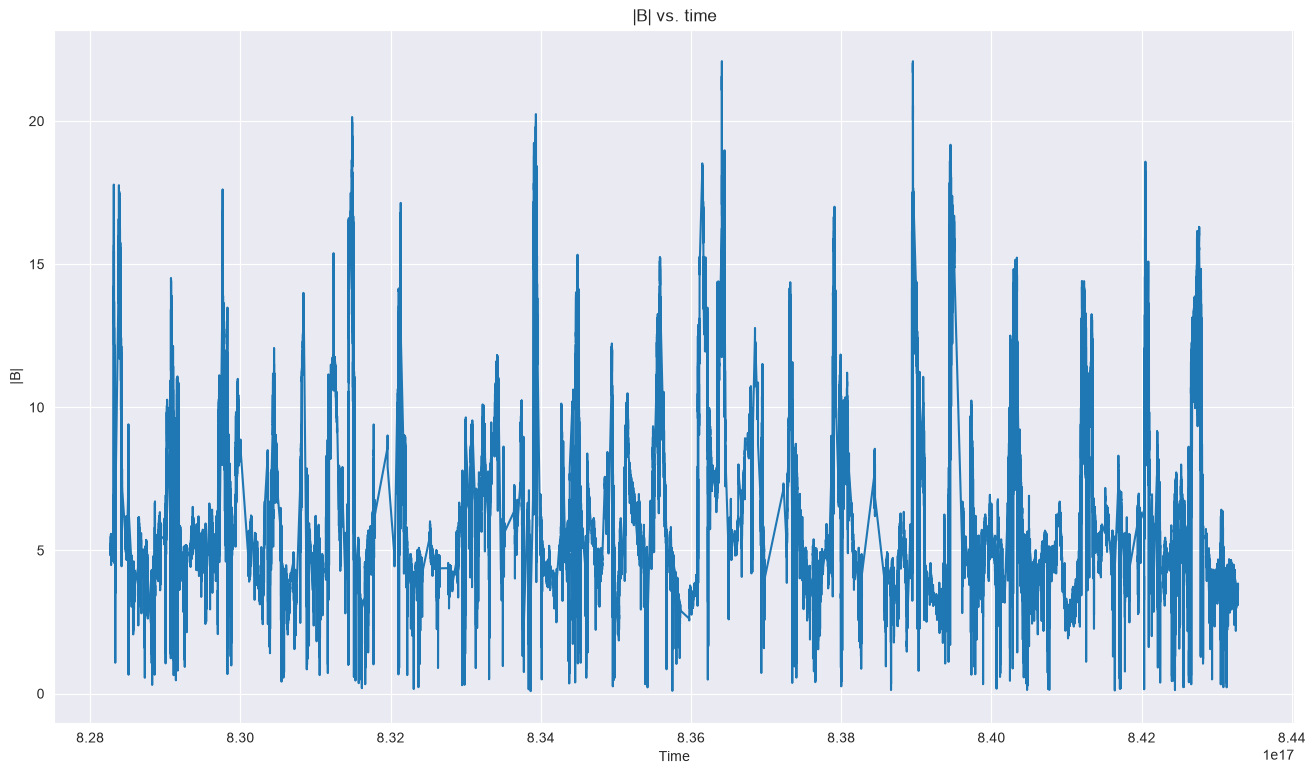

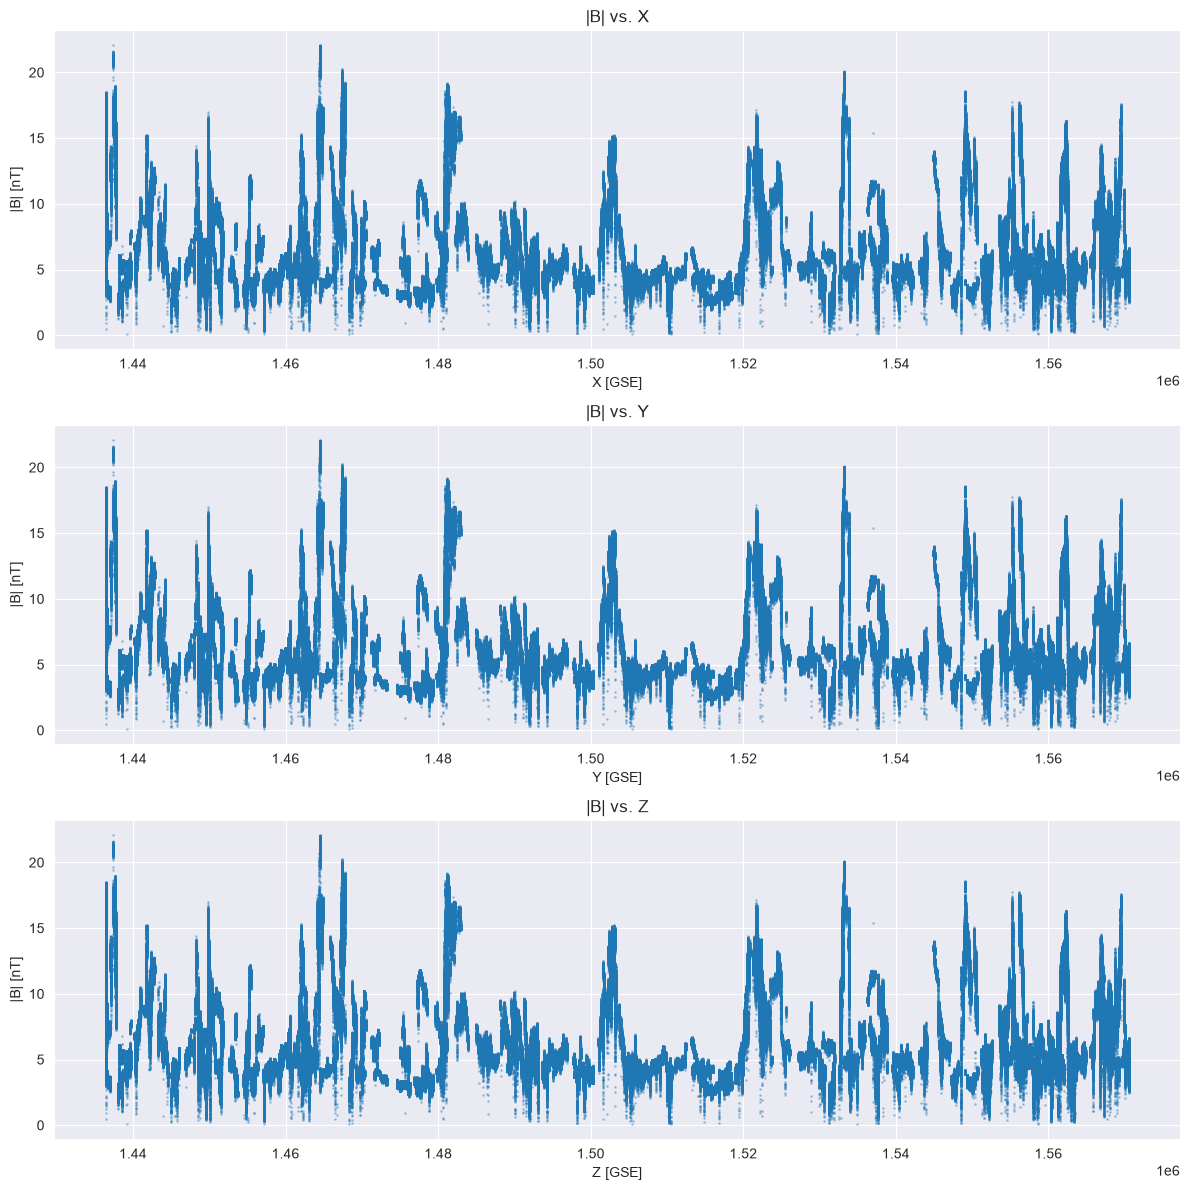

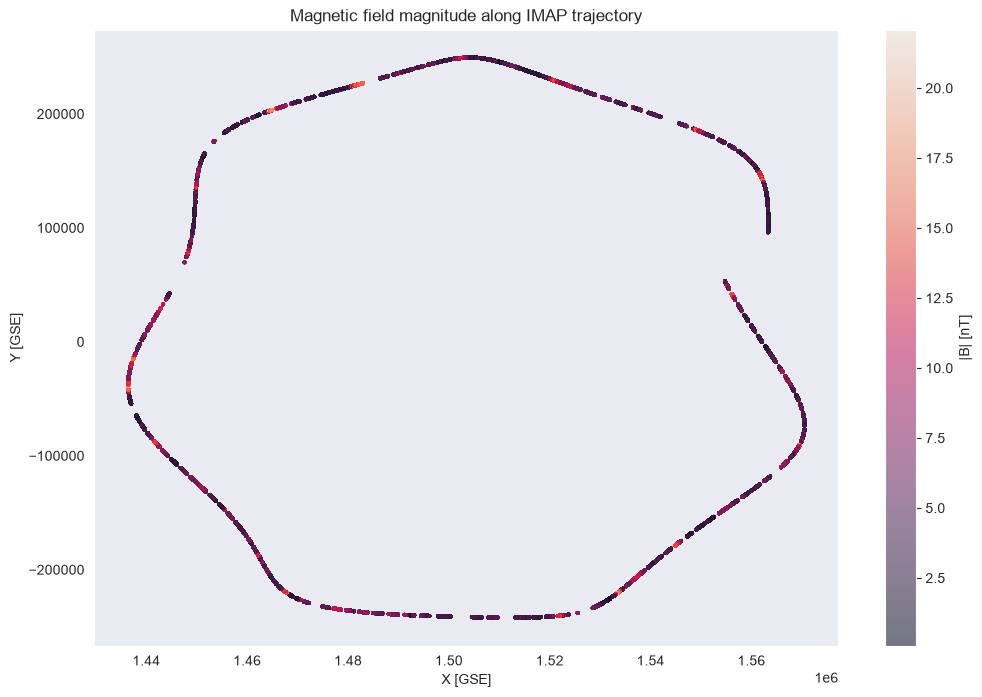

In [14]:
all_time = []
B_mag_all = []
all_position = []

for file in cdf_files:
    cdf = cdflib.CDF(f"{data_dir}/{file}")
    mag_epoch = cdf.varget("mag_epoch")
    mag_b_magnitude = cdf.varget("mag_b_magnitude")
    ephem_epoch = cdf.varget("ephemeris_epoch") # próbkowanie pozycji
    position_GSE = cdf.varget("sc_position_GSE") # pozycja GSE (Geocentric Solar Ecliptic)
    idx = np.argsort(ephem_epoch)
    ephem_epoch = ephem_epoch[idx]
    position_GSE = position_GSE[idx]
    x = np.interp(mag_epoch,ephem_epoch, position_GSE[:, 0])
    y = np.interp(mag_epoch,ephem_epoch, position_GSE[:, 1])
    z = np.interp(mag_epoch,ephem_epoch, position_GSE[:, 2])
    position_interp = np.column_stack((x, y, z))
    all_time.append(mag_epoch) # czas rejestracji zmiany pola magnetycznego
    B_mag_all.append(mag_b_magnitude) # pole magnetyczne wokół imapa
    all_position.append(position_interp)

all_time = np.concatenate(all_time)
B_mag_all = np.concatenate(B_mag_all)
all_position = np.concatenate(all_position)
idx = np.argsort(all_time)
all_time = all_time[idx]
B_mag_all = B_mag_all[idx]
all_position = all_position[idx]
valid = np.isfinite(B_mag_all) & (B_mag_all != -1e31)
all_time = all_time[valid]
B_mag_all = B_mag_all[valid]
all_position = all_position[valid]

x = all_position[:, 0]
y = all_position[:, 1]
z = all_position[:, 2]
plt.figure(figsize=(16, 9))
plt.plot(all_time, B_mag_all)
plt.xlabel("Time")
plt.ylabel("|B|")
plt.title("|B| vs. time")
plt.show()
fig, axes = plt.subplots(3, 1, figsize=(12,12))
axes[0].scatter(x, B_mag_all, s=1, alpha=0.3)
axes[0].set_xlabel("X [GSE]")
axes[0].set_ylabel("|B| [nT]")
axes[0].set_title("|B| vs. X")
axes[1].scatter(x, B_mag_all, s=1, alpha=0.3)
axes[1].set_xlabel("Y [GSE]")
axes[1].set_ylabel("|B| [nT]")
axes[1].set_title("|B| vs. Y")
axes[2].scatter(x, B_mag_all, s=1, alpha=0.3)
axes[2].set_xlabel("Z [GSE]")
axes[2].set_ylabel("|B| [nT]")
axes[2].set_title("|B| vs. Z")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 8))
scatter = plt.scatter(x, y, c=B_mag_all, s=3, alpha=0.5)
plt.xlabel("X [GSE]")
plt.ylabel("Y [GSE]")
plt.title("Magnetic field magnitude along IMAP trajectory")
plt.colorbar(scatter, label="|B| [nT]")
plt.grid()
plt.show()

In [5]:
from scipy.signal import find_peaks
peaks, _ = find_peaks(y, distance=10000)
troughs, _ = find_peaks(-y, distance=10000)
print(all_time[peaks])
print(all_position[troughs])

NameError: name 'y' is not defined

## HIT
HIT - High-energy Ion Telescope

This instrument collects a variety of particles generated by the solar wind. Because of its design consisting of multiple aparatures/openings leading to silicon-based detectors this device can not only detect but define the type of a detected ion.

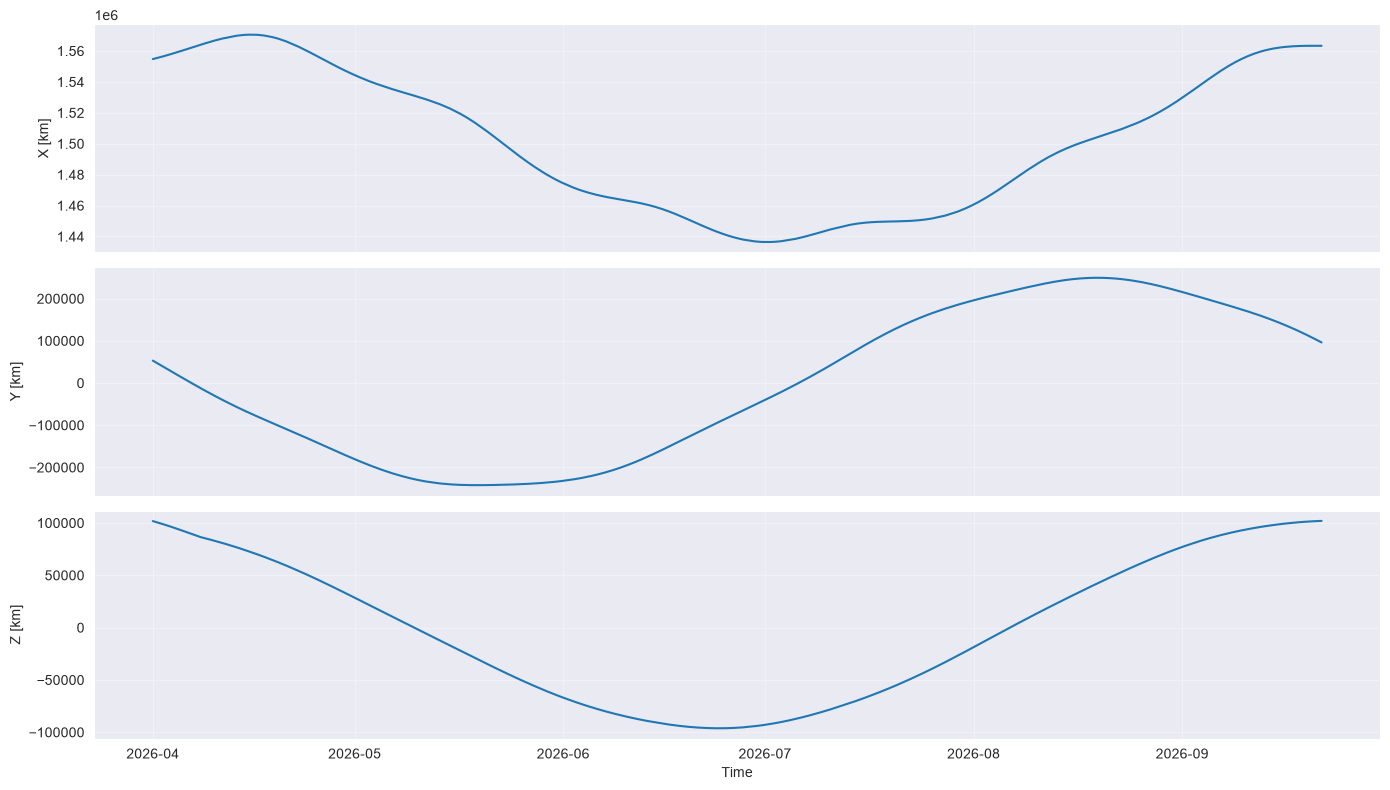

In [13]:
all_time = []
all_B_mag = []
all_x = []
all_y = []
all_z = []

for file in cdf_files:
    cdf = cdflib.CDF(f"{data_dir}/{file}")
    mag_epoch = cdf.varget("mag_epoch")
    ephem_epoch = cdf.varget("ephemeris_epoch")
    position_GSE = cdf.varget("sc_position_GSE")
    idx = np.argsort(ephem_epoch)
    ephem_epoch = ephem_epoch[idx]
    position_GSE = position_GSE[idx]
    all_x.append(np.interp(mag_epoch, ephem_epoch, position_GSE[:, 0]))
    all_y.append(np.interp(mag_epoch, ephem_epoch, position_GSE[:, 1]))
    all_z.append(np.interp(mag_epoch, ephem_epoch, position_GSE[:, 2]))
    all_time.append(mag_epoch)
    all_B_mag.append(cdf.varget("mag_B_magnitude"))

all_time = np.concatenate(all_time)
all_B_mag = np.concatenate(all_B_mag)
all_x = np.concatenate(all_x)
all_y = np.concatenate(all_y)
all_z = np.concatenate(all_z)
idx = np.argsort(all_time)
all_time = all_time[idx]
all_B_mag = all_B_mag[idx]
all_x = all_x[idx]
all_y = all_y[idx]
all_z = all_z[idx]
time = cdflib.cdfepoch.to_datetime(all_time)
fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)

axes[0].plot(time, all_x)
axes[0].set_ylabel("X [km]")
axes[0].grid(True, alpha=0.3)
axes[1].plot(time, all_y)
axes[1].set_ylabel("Y [km]")
axes[1].grid(True, alpha=0.3)
axes[2].plot(time, all_z)
axes[2].set_ylabel("Z [km]")
axes[2].set_xlabel("Time")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

TypeError: list indices must be integers or slices, not tuple